# Part 1 – Exploration (EDA)

This notebook section performs the first part of the final project: **data exploration** for the Regional Logistics Transfers binary-classification task.

The target variable is `is_delayed`: 1 means the transfer was delayed by more than 30 minutes, and 0 means it was not delayed by more than 30 minutes.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

TRAIN_PATH = 'regional_logistics_transfers_train.csv'
TEST_PATH = 'regional_logistics_transfers_test.csv'

train_raw = pd.read_csv(TRAIN_PATH)
test_raw = pd.read_csv(TEST_PATH)

print('Train shape:', train_raw.shape)
print('Test shape:', test_raw.shape)
display(train_raw.head())

Train shape: (51056, 23)
Test shape: (7555, 22)


,operation_date,day_of_week,scheduled_dispatch_time,expected_dispatch_delay_minutes,scheduled_arrival_time,source_facility,source_region,destination_facility,destination_region,logistics_provider,scheduled_travel_time_minutes,route_distance_miles,expected_provider_delay_minutes,expected_weather_disruption_minutes,expected_network_congestion_delay_minutes,expected_inspection_delay_minutes,expected_previous_transfer_delay_minutes,internal_metric_a,internal_metric_b,internal_timestamp_a,internal_timestamp_b,internal_operational_score,is_delayed
0,2024-04-01,1,830,2.0000,1217,FACILITY_298,REGION_005,FACILITY_091,REGION_006,UA,180.0000,"1,112.0000",0.0000,0.0000,0.0000,0.0000,0,NaN,4.0000,900.0000,"1,202.0000",52.5421,0
1,2024-04-01,1,1500,-7.0000,1642,FACILITY_112,REGION_029,FACILITY_273,REGION_032,9E,110.0000,478.4000,0.0000,0.0000,0.0000,0.0000,0,14.0000,4.0000,"1,451.0000","1,616.0000",58.1696,0
2,2024-04-01,1,1340,-3.0000,1522,FACILITY_273,REGION_032,FACILITY_174,REGION_031,9E,110.0000,491.0000,0.0000,0.0000,0.0000,0.0000,0,16.0000,5.0000,"1,342.0000","1,537.0000",57.7022,0
3,2024-04-01,1,1325,-11.0000,1501,FACILITY_159,REGION_048,FACILITY_099,REGION_021,9E,104.0000,440.4000,0.0000,NaN,NaN,0.0000,0,14.0000,6.0000,"1,220.0000","1,427.0000",51.5490,0
4,2024-04-01,1,1012,-5.0000,1200,FACILITY_099,REGION_021,FACILITY_174,REGION_031,9E,117.0000,585.3000,0.0000,0.0000,0.0000,0.0000,0,23.0000,NaN,"1,055.0000","1,202.0000",61.8029,0


## 1. Basic structure of the data

Before looking for patterns, I first check the number of rows and columns, data types, target balance, missing values, and whether the train/test columns match.

In [5]:
print('Train columns:')
print(train_raw.columns.tolist())
print('\nTest columns:')
print(test_raw.columns.tolist())

print('\nColumns in train but not in test:')
print(sorted(set(train_raw.columns) - set(test_raw.columns)))

print('\nData types:')
display(train_raw.dtypes.to_frame('dtype'))

Train columns:
['operation_date', 'day_of_week', 'scheduled_dispatch_time', 'expected_dispatch_delay_minutes', 'scheduled_arrival_time', 'source_facility', 'source_region', 'destination_facility', 'destination_region', 'logistics_provider', 'scheduled_travel_time_minutes', 'route_distance_miles', 'expected_provider_delay_minutes', 'expected_weather_disruption_minutes', 'expected_network_congestion_delay_minutes', 'expected_inspection_delay_minutes', 'expected_previous_transfer_delay_minutes', 'internal_metric_a', 'internal_metric_b', 'internal_timestamp_a', 'internal_timestamp_b', 'internal_operational_score', 'is_delayed']

Test columns:
['operation_date', 'day_of_week', 'scheduled_dispatch_time', 'expected_dispatch_delay_minutes', 'scheduled_arrival_time', 'source_facility', 'source_region', 'destination_facility', 'destination_region', 'logistics_provider', 'scheduled_travel_time_minutes', 'route_distance_miles', 'expected_provider_delay_minutes', 'expected_weather_disruption_minute

,dtype
operation_date,object
day_of_week,int64
scheduled_dispatch_time,int64
expected_dispatch_delay_minutes,float64
scheduled_arrival_time,int64
source_facility,object
source_region,object
destination_facility,object
destination_region,object
logistics_provider,object


,count,percent
is_delayed,,
0,43913,86.0100
1,7143,13.9900


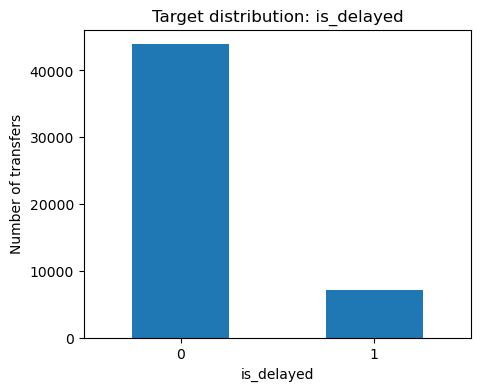

In [7]:
target_counts = train_raw['is_delayed'].value_counts().sort_index()
target_rate = train_raw['is_delayed'].value_counts(normalize=True).sort_index()
target_summary = pd.DataFrame({
    'count': target_counts,
    'percent': (100 * target_rate).round(2)
})
display(target_summary)

plt.figure(figsize=(5, 4))
target_summary['count'].plot(kind='bar')
plt.title('Target distribution: is_delayed')
plt.xlabel('is_delayed')
plt.ylabel('Number of transfers')
plt.xticks(rotation=0)
plt.show()

**Observation:** the target is imbalanced. Only about **14%** of the transfers are delayed by more than 30 minutes. This means accuracy alone will not be enough later; AUC is a better metric for this project.

In [9]:
missing_train = (train_raw.isna().mean() * 100).sort_values(ascending=False).to_frame('missing_percent_train')
missing_test = (test_raw.isna().mean() * 100).sort_values(ascending=False).to_frame('missing_percent_test')
missing_summary = missing_train.join(missing_test, how='outer').fillna(0).round(2)
display(missing_summary[missing_summary.max(axis=1) > 0])

,missing_percent_train,missing_percent_test
expected_dispatch_delay_minutes,1.2200,0.3800
expected_inspection_delay_minutes,11.9900,11.9900
expected_network_congestion_delay_minutes,8.0100,7.9800
expected_provider_delay_minutes,7.0000,6.9900
expected_weather_disruption_minutes,10.0000,10.0100
internal_metric_a,16.3000,15.4600
internal_metric_b,11.3200,10.3900
internal_timestamp_a,1.3100,0.4000
internal_timestamp_b,1.3300,0.4100


**Observation:** missing values are concentrated in several numerical columns, especially `internal_metric_a`, `expected_inspection_delay_minutes`, `internal_metric_b`, and some expected-delay variables. This will be important in the preprocessing part.

## 2. Small cleaning for exploration only

Some categorical values contain leading/trailing spaces. For example, `"B6"` and `"B6 "` should represent the same logistics provider. In this exploration, I strip spaces before grouping. This is also an important preprocessing decision for the next part.

In [11]:
train = train_raw.copy()
test = test_raw.copy()

object_cols = train.select_dtypes(include='object').columns.tolist()

space_issue = []
for col in object_cols:
    n_before = train[col].nunique(dropna=True)
    train[col] = train[col].str.strip()
    if col in test.columns:
        test[col] = test[col].str.strip()
    n_after = train[col].nunique(dropna=True)
    space_issue.append({'column': col, 'unique_before_strip': n_before, 'unique_after_strip': n_after})

space_issue = pd.DataFrame(space_issue)
display(space_issue)

,column,unique_before_strip,unique_after_strip
0,operation_date,7,7
1,source_facility,40,40
2,source_region,47,24
3,destination_facility,40,40
4,destination_region,48,24
5,logistics_provider,28,15


**Observation:** stripping spaces reduces the number of unique values in several categorical variables, especially `logistics_provider`, `source_region`, and `destination_region`. Not doing this would split the same category into two artificial categories.

## 3. Date and time exploration

The scheduled times are written in HHMM format. For better analysis, I convert them to minutes from midnight and also extract the dispatch hour.

In [13]:
def hhmm_to_minutes(series):
    """Convert HHMM numeric values into minutes from midnight."""
    return (series // 100) * 60 + (series % 100)

for col in ['scheduled_dispatch_time', 'scheduled_arrival_time', 'internal_timestamp_a', 'internal_timestamp_b']:
    if col in train.columns:
        train[col + '_minutes'] = hhmm_to_minutes(train[col])
    if col in test.columns:
        test[col + '_minutes'] = hhmm_to_minutes(test[col])

train['dispatch_hour'] = (train['scheduled_dispatch_time_minutes'] // 60).astype(int)
test['dispatch_hour'] = (test['scheduled_dispatch_time_minutes'] // 60).astype(int)

print('Train dates:')
display(train.groupby('operation_date')['is_delayed'].agg(['count', 'mean']).rename(columns={'mean':'delay_rate'}))

print('Test dates:')
display(test['operation_date'].value_counts().to_frame('count'))

Train dates:


,count,delay_rate
operation_date,,
2024-04-01,7469,0.1210
2024-04-02,7214,0.1083
2024-04-03,7265,0.2396
2024-04-04,7558,0.2057
2024-04-05,7576,0.1307
2024-04-06,6592,0.0859
2024-04-07,7382,0.0821


Test dates:


,count
operation_date,
2024-04-08,7555


**Observation:** the train data covers one week, while the test data contains the next date. Therefore, using the raw `operation_date` as a categorical feature may not generalize well. More general features such as `day_of_week` and time-of-day are safer.

,count,delay_rate
dispatch_hour,,
7,5060,0.0702
8,4583,0.0858
9,3578,0.0880
10,3813,0.1052
11,3608,0.1264
12,3718,0.1307
13,3675,0.1401
14,3409,0.1517
15,3694,0.1741


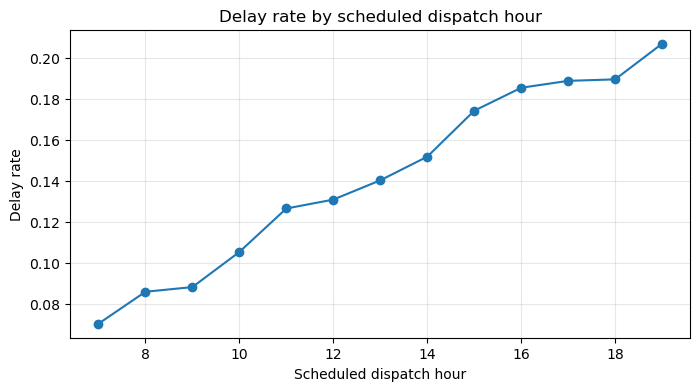

In [15]:
dispatch_hour_rates = train.groupby('dispatch_hour')['is_delayed'].agg(['count', 'mean']).rename(columns={'mean': 'delay_rate'})
display(dispatch_hour_rates)

plt.figure(figsize=(8, 4))
dispatch_hour_rates['delay_rate'].plot(kind='line', marker='o')
plt.title('Delay rate by scheduled dispatch hour')
plt.xlabel('Scheduled dispatch hour')
plt.ylabel('Delay rate')
plt.grid(True, alpha=0.3)
plt.show()

**Answer – dispatch hours:** yes, there are clear differences by scheduled dispatch hour. The delay rate is lowest in the morning and increases throughout the day. In the data, transfers scheduled around **07:00** have a delay rate of about **7%**, while transfers around **19:00** have a delay rate of about **20.7%**.

## 4. Geographic regions and logistics providers

Here I compare delay rates between providers and between source/destination regions. To avoid being misled by very tiny groups, I display groups with at least 100 observations.

In [17]:
def group_delay_table(df, group_col, min_count=100):
    table = (
        df.groupby(group_col)['is_delayed']
          .agg(count='size', delay_rate='mean')
          .query('count >= @min_count')
          .sort_values('delay_rate', ascending=False)
    )
    return table

provider_rates = group_delay_table(train, 'logistics_provider', min_count=100)
source_region_rates = group_delay_table(train, 'source_region', min_count=100)
destination_region_rates = group_delay_table(train, 'destination_region', min_count=100)

print('Logistics providers:')
display(provider_rates)

print('Top source regions:')
display(source_region_rates.head(10))

print('Top destination regions:')
display(destination_region_rates.head(10))

Logistics providers:


,count,delay_rate
logistics_provider,,
B6,2015,0.2347
F9,1635,0.2190
OH,424,0.1604
NK,2213,0.1523
UA,8145,0.1482
YX,1484,0.1442
9E,599,0.1386
AA,9004,0.1384
AS,2138,0.1356


Top source regions:


,count,delay_rate
source_region,,
REGION_029,1376,0.2544
REGION_020,1693,0.1931
REGION_008,5744,0.1732
REGION_031,2897,0.1719
REGION_032,2363,0.1502
REGION_009,2630,0.1449
REGION_012,3280,0.1430
REGION_006,2471,0.1412
REGION_037,1092,0.1401


Top destination regions:


,count,delay_rate
destination_region,,
REGION_029,1286,0.2185
REGION_020,1647,0.1998
REGION_008,5503,0.1843
REGION_031,2874,0.1795
REGION_037,1019,0.1511
REGION_005,6155,0.1482
REGION_012,3094,0.1474
REGION_048,1957,0.1410
REGION_009,2552,0.1344


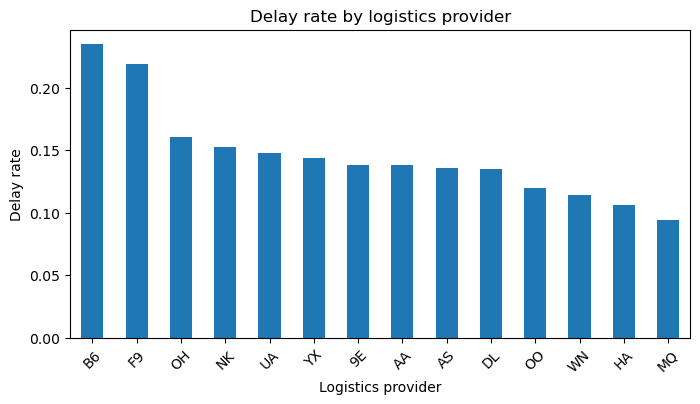

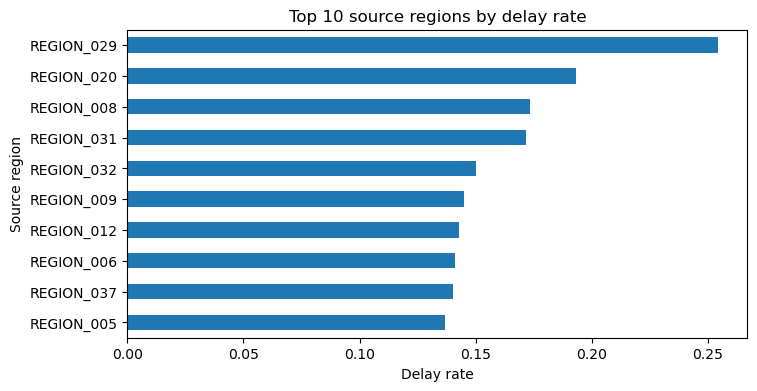

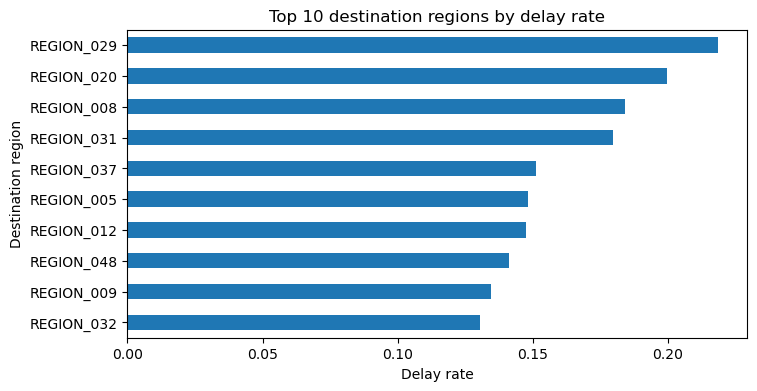

In [19]:
plt.figure(figsize=(8, 4))
provider_rates['delay_rate'].sort_values(ascending=False).plot(kind='bar')
plt.title('Delay rate by logistics provider')
plt.xlabel('Logistics provider')
plt.ylabel('Delay rate')
plt.xticks(rotation=45)
plt.show()

plt.figure(figsize=(8, 4))
source_region_rates.head(10)['delay_rate'].sort_values().plot(kind='barh')
plt.title('Top 10 source regions by delay rate')
plt.xlabel('Delay rate')
plt.ylabel('Source region')
plt.show()

plt.figure(figsize=(8, 4))
destination_region_rates.head(10)['delay_rate'].sort_values().plot(kind='barh')
plt.title('Top 10 destination regions by delay rate')
plt.xlabel('Delay rate')
plt.ylabel('Destination region')
plt.show()

**Answer – geographic regions and providers:** yes, there are meaningful differences.

* Among providers with at least 100 observations, `B6` and `F9` have the highest delay rates, around **23.5%** and **21.9%**.
* Providers such as `MQ`, `HA`, and `WN` have lower rates, roughly **9.4%–11.4%**.
* Some regions also stand out. For example, source region `REGION_029` has a high delay rate of about **25.4%**, and destination regions `REGION_029` and `REGION_020` are also relatively high.

This suggests that both provider and region variables may be useful predictors.

## 5. Departure delays and arrival-delay probability

The dataset does not contain the exact final arrival delay in minutes as a separate numeric column. Instead, the target `is_delayed` tells us whether the transfer was delayed by more than 30 minutes. Therefore, I examine whether expected dispatch delay is related to the probability of `is_delayed = 1`.

,count,delay_rate
expected_dispatch_delay_minutes,,
"(-22.001, -5.0]",13273,0.0091
"(-5.0, -2.0]",10109,0.0137
"(-2.0, 1.0]",6901,0.0165
"(1.0, 19.0]",10346,0.0414
"(19.0, 2120.0]",9806,0.6467


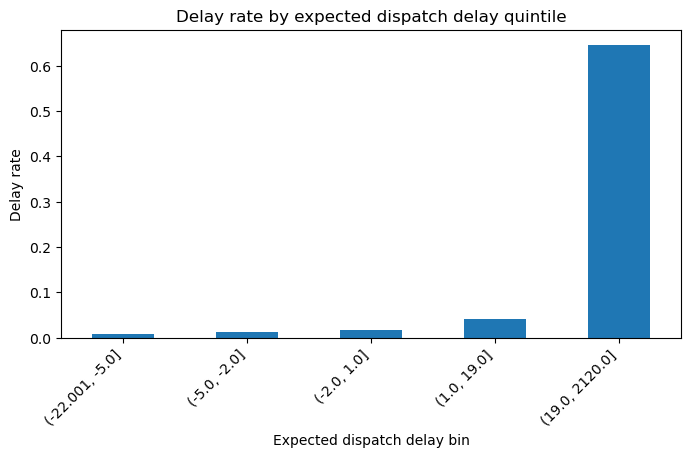

Correlation between expected_dispatch_delay_minutes and is_delayed: 0.598


In [21]:
dispatch_delay_bins = pd.qcut(train['expected_dispatch_delay_minutes'], q=5, duplicates='drop')
dispatch_delay_table = train.groupby(dispatch_delay_bins, observed=True)['is_delayed'].agg(['count', 'mean']).rename(columns={'mean':'delay_rate'})
display(dispatch_delay_table)

plt.figure(figsize=(8, 4))
dispatch_delay_table['delay_rate'].plot(kind='bar')
plt.title('Delay rate by expected dispatch delay quintile')
plt.xlabel('Expected dispatch delay bin')
plt.ylabel('Delay rate')
plt.xticks(rotation=45, ha='right')
plt.show()

corr_dispatch_target = train[['expected_dispatch_delay_minutes', 'is_delayed']].corr().iloc[0, 1]
print(f'Correlation between expected_dispatch_delay_minutes and is_delayed: {corr_dispatch_target:.3f}')

**Answer – departure delay vs arrival delay:** yes, this is one of the strongest relationships in the data. The correlation between `expected_dispatch_delay_minutes` and `is_delayed` is about **0.598**. In the highest dispatch-delay quintile, where expected dispatch delay is above about 19 minutes, the delay rate is about **64.7%**. In the lower bins, the delay rate is close to **1%–4%**.

This means departure delay has a very strong effect on the probability of a significant arrival delay.

## 6. Route distance and scheduled travel time

Now I check whether long routes are more likely to be delayed.

route_distance_miles


,count,delay_rate
route_distance_miles,,
"(91.999, 556.6]",10242,0.1365
"(556.6, 860.2]",10193,0.1448
"(860.2, 1159.2]",10213,0.1381
"(1159.2, 1697.4]",10244,0.1388
"(1697.4, 14341.7]",10164,0.1414


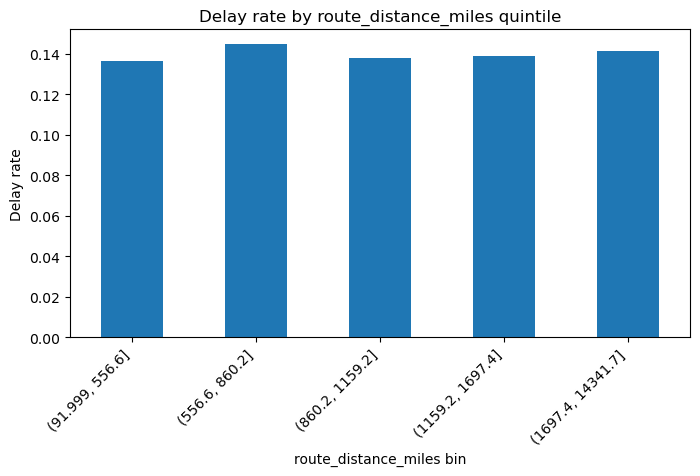

scheduled_travel_time_minutes


,count,delay_rate
scheduled_travel_time_minutes,,
"(54.999, 113.0]",10535,0.1334
"(113.0, 149.0]",9992,0.1435
"(149.0, 185.0]",10245,0.1378
"(185.0, 242.0]",10157,0.1426
"(242.0, 764.0]",10127,0.1426


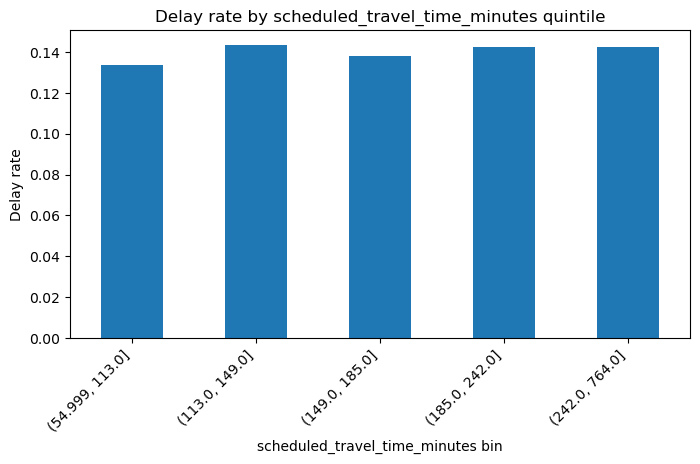

Correlations with target:


,corr_with_target
route_distance_miles,0.0063
scheduled_travel_time_minutes,0.0097


In [23]:
for col in ['route_distance_miles', 'scheduled_travel_time_minutes']:
    bins = pd.qcut(train[col], q=5, duplicates='drop')
    table = train.groupby(bins, observed=True)['is_delayed'].agg(['count', 'mean']).rename(columns={'mean':'delay_rate'})
    print(col)
    display(table)
    plt.figure(figsize=(8, 4))
    table['delay_rate'].plot(kind='bar')
    plt.title(f'Delay rate by {col} quintile')
    plt.xlabel(col + ' bin')
    plt.ylabel('Delay rate')
    plt.xticks(rotation=45, ha='right')
    plt.show()

print('Correlations with target:')
display(train[['route_distance_miles', 'scheduled_travel_time_minutes', 'is_delayed']].corr()['is_delayed'].drop('is_delayed').to_frame('corr_with_target'))

**Answer – route distance:** route distance does **not** appear to strongly affect delays in this dataset. Delay rates across distance quintiles are very similar, around **13.6%–14.5%**, and the correlation with the target is close to zero. Scheduled travel time also has a very weak relationship with the target.

## 7. Correlations between delay-related variables

I now check whether different delay variables are correlated with each other and with the target.

,expected_dispatch_delay_minutes,expected_provider_delay_minutes,expected_weather_disruption_minutes,expected_network_congestion_delay_minutes,expected_inspection_delay_minutes,expected_previous_transfer_delay_minutes
expected_dispatch_delay_minutes,1.0000,0.6680,0.2410,0.3380,0.0200,0.6350
expected_provider_delay_minutes,0.6680,1.0000,-0.0050,0.0140,-0.0020,0.0480
expected_weather_disruption_minutes,0.2410,-0.0050,1.0000,0.0250,-0.0010,0.0530
expected_network_congestion_delay_minutes,0.3380,0.0140,0.0250,1.0000,0.0060,0.0350
expected_inspection_delay_minutes,0.0200,-0.0020,-0.0010,0.0060,1.0000,-0.0020
expected_previous_transfer_delay_minutes,0.6350,0.0480,0.0530,0.0350,-0.0020,1.0000


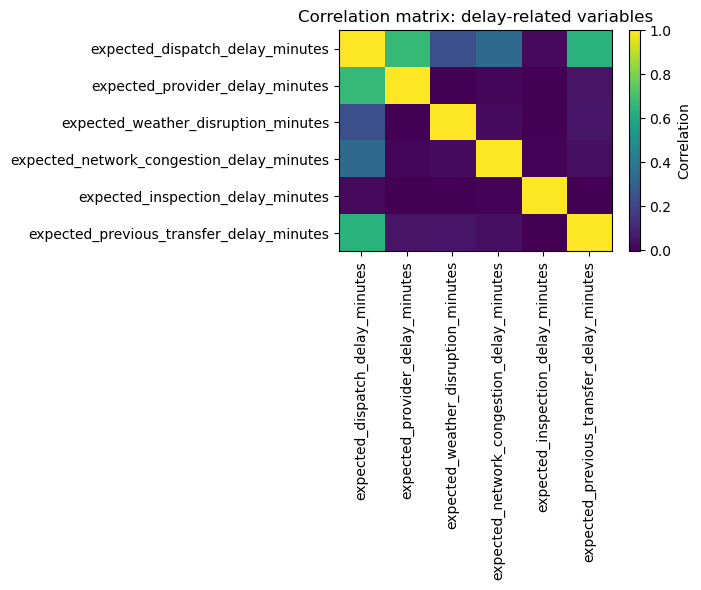

,corr_with_target
expected_dispatch_delay_minutes,0.5983
expected_previous_transfer_delay_minutes,0.4588
expected_network_congestion_delay_minutes,0.3802
expected_provider_delay_minutes,0.3056
internal_timestamp_a_minutes,0.2455
internal_timestamp_a,0.2452
internal_metric_a,0.2377
scheduled_dispatch_time_minutes,0.1291
scheduled_dispatch_time,0.1289
dispatch_hour,0.1284


In [25]:
delay_cols = [
    'expected_dispatch_delay_minutes',
    'expected_provider_delay_minutes',
    'expected_weather_disruption_minutes',
    'expected_network_congestion_delay_minutes',
    'expected_inspection_delay_minutes',
    'expected_previous_transfer_delay_minutes'
]

corr_delay = train[delay_cols].corr()
display(corr_delay.round(3))

plt.figure(figsize=(7, 6))
plt.imshow(corr_delay, aspect='auto')
plt.colorbar(label='Correlation')
plt.xticks(range(len(delay_cols)), delay_cols, rotation=90)
plt.yticks(range(len(delay_cols)), delay_cols)
plt.title('Correlation matrix: delay-related variables')
plt.tight_layout()
plt.show()

num_cols = train.select_dtypes(include=[np.number]).columns.tolist()
corr_with_target = train[num_cols].corr(numeric_only=True)['is_delayed'].drop('is_delayed')
corr_with_target = corr_with_target.reindex(corr_with_target.abs().sort_values(ascending=False).index)
display(corr_with_target.head(20).to_frame('corr_with_target'))

**Answer – correlations between delay types:** yes, some delay variables are strongly related.

* `expected_dispatch_delay_minutes` is strongly correlated with `expected_provider_delay_minutes` (**0.668**).
* `expected_dispatch_delay_minutes` is also strongly correlated with `expected_previous_transfer_delay_minutes` (**0.635**).
* The correlation between dispatch delay and network congestion is moderate (**0.338**).
* Inspection delay is almost uncorrelated with the other delay variables.

The strongest numerical correlations with the target are from dispatch delay, previous-transfer delay, network congestion delay, provider delay, and some internal timestamp/metric variables.

## 8. Zero-inflated delay variables

Many delay variables are mostly zero, with a small number of positive values. This can still be very useful because a positive value often indicates a much higher risk of delay.

In [27]:
zero_summary_rows = []
for col in delay_cols[1:]:
    s = train[col]
    status = pd.Series(np.where(s.isna(), 'missing', np.where(s == 0, 'zero', 'positive')), index=train.index)
    status_table = train.groupby(status)['is_delayed'].agg(count='size', delay_rate='mean')
    status_table['feature'] = col
    zero_summary_rows.append(status_table.reset_index().rename(columns={'index':'status'}))

zero_summary = pd.concat(zero_summary_rows, ignore_index=True)
display(zero_summary[['feature', 'status', 'count', 'delay_rate']])

,feature,status,count,delay_rate
0,expected_provider_delay_minutes,missing,3576,0.1376
1,expected_provider_delay_minutes,positive,5690,0.6513
2,expected_provider_delay_minutes,zero,41790,0.0705
3,expected_weather_disruption_minutes,missing,5104,0.1395
4,expected_weather_disruption_minutes,positive,368,0.8315
5,expected_weather_disruption_minutes,zero,45584,0.1344
6,expected_network_congestion_delay_minutes,missing,4090,0.1372
7,expected_network_congestion_delay_minutes,positive,5771,0.6013
8,expected_network_congestion_delay_minutes,zero,41195,0.0755
9,expected_inspection_delay_minutes,missing,6123,0.1467


**Observation:** positive values in expected provider delay, expected weather disruption, expected network congestion delay, and previous transfer delay are associated with much higher delay rates than zero values. This suggests that creating binary indicators such as `has_provider_delay` or `has_previous_delay` may be useful later.

## 9. Anonymous/internal variables

The dataset contains anonymous internal variables. I check whether they show a visible relationship with the target.

internal_metric_a
Correlation with target: 0.238


,count,delay_rate
internal_metric_a,,
"(0.999, 12.0]",9843,0.0988
"(12.0, 15.0]",9597,0.1105
"(15.0, 18.0]",7762,0.1196
"(18.0, 23.0]",7603,0.1424
"(23.0, 176.0]",7931,0.2539


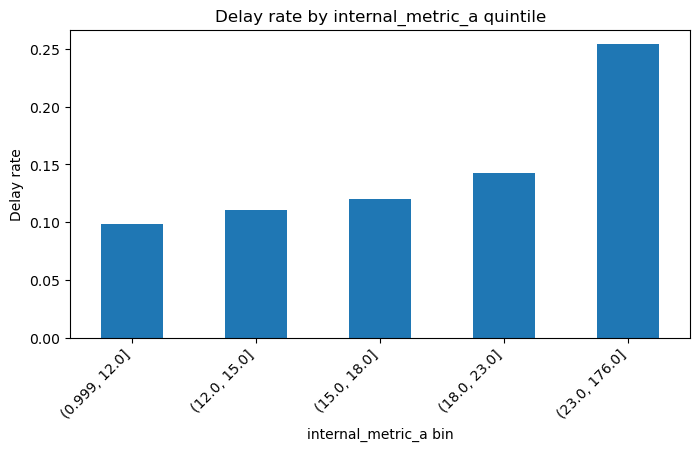

internal_metric_b
Correlation with target: 0.1


,count,delay_rate
internal_metric_b,,
"(0.999, 5.0]",14910,0.1213
"(5.0, 6.0]",5373,0.1355
"(6.0, 8.0]",8480,0.1369
"(8.0, 11.0]",7671,0.1510
"(11.0, 160.0]",8840,0.1786


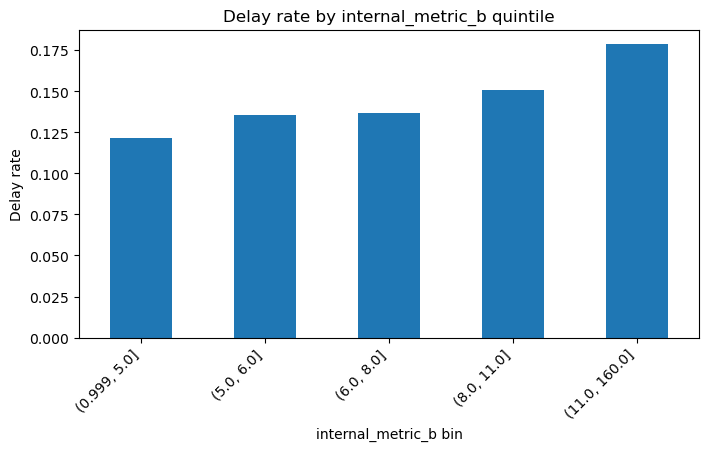

internal_timestamp_a_minutes
Correlation with target: 0.245


,count,delay_rate
internal_timestamp_a_minutes,,
"(-0.001, 572.0]",10106,0.0431
"(572.0, 740.0]",10085,0.0943
"(740.0, 914.0]",10080,0.1284
"(914.0, 1083.0]",10090,0.1550
"(1083.0, 1439.0]",10026,0.2890


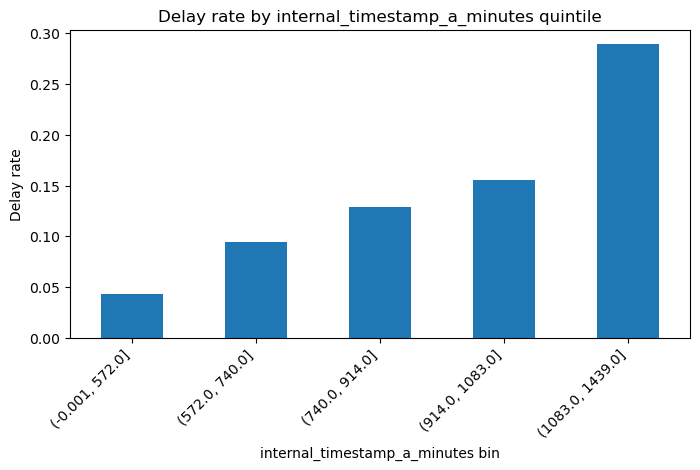

internal_timestamp_b_minutes
Correlation with target: 0.106


,count,delay_rate
internal_timestamp_b_minutes,,
"(-0.001, 685.0]",10104,0.0924
"(685.0, 866.0]",10074,0.0899
"(866.0, 1039.0]",10104,0.1123
"(1039.0, 1202.0]",10067,0.1572
"(1202.0, 1439.0]",10027,0.2578


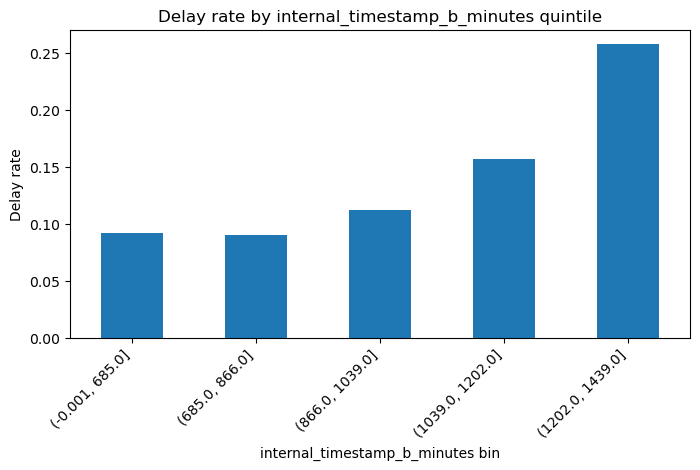

internal_operational_score
Correlation with target: -0.001


,count,delay_rate
internal_operational_score,,
"(7.069, 41.591]",10212,0.1350
"(41.591, 47.408]",10211,0.1433
"(47.408, 52.476]",10211,0.1419
"(52.476, 58.428]",10211,0.1441
"(58.428, 93.624]",10211,0.1352


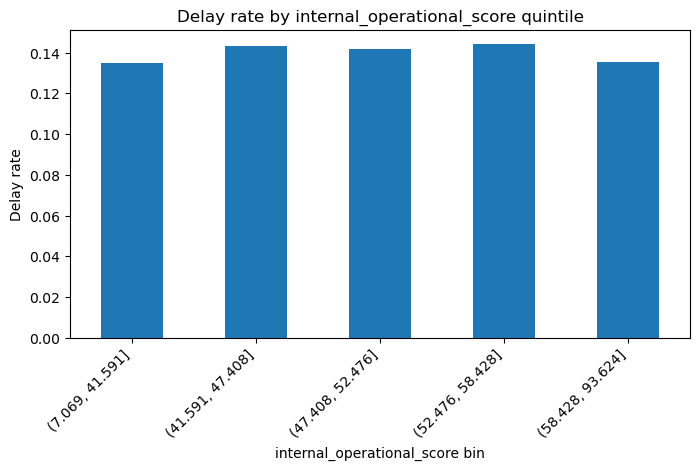

In [29]:
anonymous_cols = [
    'internal_metric_a',
    'internal_metric_b',
    'internal_timestamp_a_minutes',
    'internal_timestamp_b_minutes',
    'internal_operational_score'
]

for col in anonymous_cols:
    if col not in train.columns:
        continue
    print(col)
    print('Correlation with target:', round(train[[col, 'is_delayed']].corr().iloc[0, 1], 3))
    bins = pd.qcut(train[col], q=5, duplicates='drop')
    table = train.groupby(bins, observed=True)['is_delayed'].agg(['count', 'mean']).rename(columns={'mean':'delay_rate'})
    display(table)
    plt.figure(figsize=(8, 4))
    table['delay_rate'].plot(kind='bar')
    plt.title(f'Delay rate by {col} quintile')
    plt.xlabel(col + ' bin')
    plt.ylabel('Delay rate')
    plt.xticks(rotation=45, ha='right')
    plt.show()

**Answer – anonymous/internal features:** yes, some anonymous features look useful.

* `internal_metric_a` seems important: the delay rate increases from about **9.9%** in the lowest bin to about **25.4%** in the highest bin.
* `internal_metric_b` has a weaker but still visible relationship: the delay rate increases from about **12.1%** to about **17.9%**.
* `internal_timestamp_a` also has a noticeable positive correlation with the target.
* `internal_operational_score` looks weak because its delay rate stays almost flat across bins.

## 10. Features that look weak or risky based on exploration

Based only on this exploration, the following features look weak or require caution:

* `route_distance_miles` – almost no correlation with the target and nearly flat delay rates across bins.
* `scheduled_travel_time_minutes` – weak relationship with the target.
* `expected_inspection_delay_minutes` – mostly zeros and very low correlation; still, the rare positive cases may contain some signal.
* `internal_operational_score` – delay rate is almost flat across bins.
* Raw `operation_date` – test data is on a new date, so using the raw date as a category may overfit. It is better to use general date/time features such as `day_of_week`.

These features should not necessarily be removed immediately, but they should be tested during model training and feature selection.

# Summary of Part 1 answers

1. **Differences by regions/providers:** yes. Some providers and regions have much higher delay rates than others.
2. **Dispatch hours:** yes. Delay probability increases later in the day.
3. **Departure delay vs arrival delay:** very strong relationship. Larger expected dispatch delay sharply increases the probability of `is_delayed = 1`.
4. **Route distance:** little to no visible effect.
5. **Correlation between delay types:** yes. Dispatch delay is strongly correlated with provider delay and previous-transfer delay.
6. **Anonymous features:** `internal_metric_a`, `internal_metric_b`, and `internal_timestamp_a` look useful. `internal_operational_score` looks weak.
7. **Low-relevance features:** route distance, scheduled travel time, internal operational score, and raw operation date look weak/risky based on EDA.

These findings will guide the preprocessing and modeling stages.

**Part 2 + Part 3**

This notebook continues the Regional Logistics Transfers binary classification project.

**Part 2:** preprocessing pipeline: missing values, outliers, normalization, categorical variables, feature engineering, dimensionality, and application to the test set.

**Part 3:** training several machine-learning models:
- One required basic model: **Logistic Regression**
- Three advanced models: **Decision Tree**, **Random Forest**, and **Linear Support Vector Machine**

The evaluation here is a first validation check using ROC-AUC. The full K-Fold ROC analysis belongs to Part 4.

In [34]:
# =========================
# 1. Imports and settings
# =========================

from pathlib import Path
from time import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 120)

RANDOM_STATE = 42

In [36]:
# =========================
# 2. Load train and test data
# =========================

# Change this path if the files are stored in another folder.
DATA_DIR = Path(".")

# This fallback is useful only when running inside this environment.
if not (DATA_DIR / "regional_logistics_transfers_train.csv").exists():
    DATA_DIR = Path("/mnt/data")

train_path = DATA_DIR / "regional_logistics_transfers_train.csv"
test_path = DATA_DIR / "regional_logistics_transfers_test.csv"

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

target_col = "is_delayed"
y = train_df[target_col].astype(int)
X = train_df.drop(columns=[target_col])

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("Target mean / delayed rate:", round(y.mean(), 4))
train_df.head()

Train shape: (51056, 23)
Test shape: (7555, 22)
Target mean / delayed rate: 0.1399


,operation_date,day_of_week,scheduled_dispatch_time,expected_dispatch_delay_minutes,scheduled_arrival_time,source_facility,source_region,destination_facility,destination_region,logistics_provider,scheduled_travel_time_minutes,route_distance_miles,expected_provider_delay_minutes,expected_weather_disruption_minutes,expected_network_congestion_delay_minutes,expected_inspection_delay_minutes,expected_previous_transfer_delay_minutes,internal_metric_a,internal_metric_b,internal_timestamp_a,internal_timestamp_b,internal_operational_score,is_delayed
0,2024-04-01,1,830,2.0000,1217,FACILITY_298,REGION_005,FACILITY_091,REGION_006,UA,180.0000,"1,112.0000",0.0000,0.0000,0.0000,0.0000,0,NaN,4.0000,900.0000,"1,202.0000",52.5421,0
1,2024-04-01,1,1500,-7.0000,1642,FACILITY_112,REGION_029,FACILITY_273,REGION_032,9E,110.0000,478.4000,0.0000,0.0000,0.0000,0.0000,0,14.0000,4.0000,"1,451.0000","1,616.0000",58.1696,0
2,2024-04-01,1,1340,-3.0000,1522,FACILITY_273,REGION_032,FACILITY_174,REGION_031,9E,110.0000,491.0000,0.0000,0.0000,0.0000,0.0000,0,16.0000,5.0000,"1,342.0000","1,537.0000",57.7022,0
3,2024-04-01,1,1325,-11.0000,1501,FACILITY_159,REGION_048,FACILITY_099,REGION_021,9E,104.0000,440.4000,0.0000,NaN,NaN,0.0000,0,14.0000,6.0000,"1,220.0000","1,427.0000",51.5490,0
4,2024-04-01,1,1012,-5.0000,1200,FACILITY_099,REGION_021,FACILITY_174,REGION_031,9E,117.0000,585.3000,0.0000,0.0000,0.0000,0.0000,0,23.0000,NaN,"1,055.0000","1,202.0000",61.8029,0


## Part 2 — Preprocessing

The preprocessing is implemented as a single `sklearn` pipeline so the exact same steps can be fitted on the training data and then applied to validation and test data without data leakage.

Main assumptions:
1. `operation_date` is dropped as a raw feature. In the train set it represents specific dates from one week, while the test set is a later date. Keeping the raw date may cause overfitting to dates rather than learning general operational patterns.
2. HHMM time values are converted to minutes after midnight and cyclic sine/cosine features.
3. Missing values are imputed only after splitting, inside the pipeline.
4. Outliers are clipped using quantiles learned from the training split only.
5. Categorical values are one-hot encoded with `handle_unknown="ignore"`, so unseen categories in the test set do not break the code.

In [40]:
# =========================
# 3. Feature-engineering helpers
# =========================

def hhmm_to_minutes(series: pd.Series) -> pd.Series:
    """Convert HHMM values into minutes after midnight.
    Invalid HHMM values are converted to NaN and later imputed inside the pipeline.
    """
    values = pd.to_numeric(series, errors="coerce")
    hours = np.floor(values / 100)
    minutes = values % 100
    valid = values.notna() & (hours >= 0) & (hours < 24) & (minutes >= 0) & (minutes < 60)

    out = pd.Series(np.nan, index=series.index, dtype="float64")
    out.loc[valid] = hours.loc[valid] * 60 + minutes.loc[valid]
    return out


def add_features(df: pd.DataFrame) -> pd.DataFrame:
    """Create predictive features and remove raw columns that are not suitable as direct numeric inputs."""
    df = df.copy()

    dispatch_min = hhmm_to_minutes(df["scheduled_dispatch_time"])
    arrival_min = hhmm_to_minutes(df["scheduled_arrival_time"])
    ts_a_min = hhmm_to_minutes(df["internal_timestamp_a"])
    ts_b_min = hhmm_to_minutes(df["internal_timestamp_b"])

    # Direct minute representation
    df["scheduled_dispatch_minutes"] = dispatch_min
    df["scheduled_arrival_minutes"] = arrival_min
    df["internal_timestamp_a_minutes"] = ts_a_min
    df["internal_timestamp_b_minutes"] = ts_b_min

    # Hour-level features
    df["dispatch_hour"] = np.floor(dispatch_min / 60)
    df["arrival_hour"] = np.floor(arrival_min / 60)

    # Cyclic representation for time-of-day features
    for name, mins in [
        ("dispatch", dispatch_min),
        ("arrival", arrival_min),
        ("internal_timestamp_a", ts_a_min),
        ("internal_timestamp_b", ts_b_min),
    ]:
        angle = 2 * np.pi * mins / (24 * 60)
        df[f"{name}_sin"] = np.sin(angle)
        df[f"{name}_cos"] = np.cos(angle)

    # Planned clock duration, including midnight crossing
    df["planned_clock_travel_minutes"] = (arrival_min - dispatch_min) % (24 * 60)
    df["planned_vs_scheduled_travel_gap"] = df["planned_clock_travel_minutes"] - df["scheduled_travel_time_minutes"]

    # Speed-like feature: distance divided by scheduled travel time in hours
    safe_travel_hours = (df["scheduled_travel_time_minutes"] / 60).replace(0, np.nan)
    df["planned_route_speed_mph"] = df["route_distance_miles"] / safe_travel_hours

    # Aggregated expected delay features
    delay_cols = [
        "expected_dispatch_delay_minutes",
        "expected_provider_delay_minutes",
        "expected_weather_disruption_minutes",
        "expected_network_congestion_delay_minutes",
        "expected_inspection_delay_minutes",
        "expected_previous_transfer_delay_minutes",
    ]
    present_delay_cols = [col for col in delay_cols if col in df.columns]
    df["expected_delay_sum"] = df[present_delay_cols].sum(axis=1, skipna=True)
    df["expected_non_dispatch_delay_sum"] = df[
        [col for col in present_delay_cols if col != "expected_dispatch_delay_minutes"]
    ].sum(axis=1, skipna=True)

    # Interaction between weather and congestion
    df["weather_congestion_interaction"] = (
        df["expected_weather_disruption_minutes"] * df["expected_network_congestion_delay_minutes"]
    )

    # Simple relational features
    df["same_facility"] = (df["source_facility"] == df["destination_facility"]).astype(int)
    df["same_region"] = (df["source_region"] == df["destination_region"]).astype(int)

    # Drop raw HHMM and raw date columns after engineering safer representations
    columns_to_drop = [
        "scheduled_dispatch_time",
        "scheduled_arrival_time",
        "internal_timestamp_a",
        "internal_timestamp_b",
        "operation_date",
    ]
    df = df.drop(columns=[col for col in columns_to_drop if col in df.columns])
    return df


class Winsorizer(BaseEstimator, TransformerMixin):
    """Clip numeric features to lower/upper quantiles learned from the training data only."""
    def __init__(self, lower=0.01, upper=0.99):
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        X_arr = np.asarray(X, dtype=float)
        self.lower_bounds_ = np.nanquantile(X_arr, self.lower, axis=0)
        self.upper_bounds_ = np.nanquantile(X_arr, self.upper, axis=0)
        return self

    def transform(self, X):
        X_arr = np.asarray(X, dtype=float)
        return np.clip(X_arr, self.lower_bounds_, self.upper_bounds_)


def make_one_hot_encoder():
    """Compatibility helper for different scikit-learn versions."""
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)

In [42]:
# =========================
# 4. Missing values report
# =========================

missing_report = (
    train_df.isna()
    .sum()
    .to_frame("missing_count")
    .assign(missing_percent=lambda d: (100 * d["missing_count"] / len(train_df)).round(2))
    .query("missing_count > 0")
    .sort_values("missing_percent", ascending=False)
)

missing_report

,missing_count,missing_percent
internal_metric_a,8320,16.3000
expected_inspection_delay_minutes,6123,11.9900
internal_metric_b,5782,11.3200
expected_weather_disruption_minutes,5104,10.0000
expected_network_congestion_delay_minutes,4090,8.0100
expected_provider_delay_minutes,3576,7.0000
internal_timestamp_b,680,1.3300
internal_timestamp_a,669,1.3100
expected_dispatch_delay_minutes,621,1.2200


In [44]:
# =========================
# 5. Categorical variables and unseen test categories
# =========================

categorical_original_cols = [
    "source_facility",
    "source_region",
    "destination_facility",
    "destination_region",
    "logistics_provider",
]

category_report_rows = []
for col in categorical_original_cols:
    train_values = set(train_df[col].dropna().unique())
    test_values = set(test_df[col].dropna().unique())
    category_report_rows.append({
        "feature": col,
        "train_unique": len(train_values),
        "test_unique": len(test_values),
        "unseen_in_test": len(test_values - train_values),
        "missing_train": int(train_df[col].isna().sum()),
        "missing_test": int(test_df[col].isna().sum()),
    })

category_report = pd.DataFrame(category_report_rows)
category_report

,feature,train_unique,test_unique,unseen_in_test,missing_train,missing_test
0,source_facility,40,40,0,0,0
1,source_region,47,46,1,0,0
2,destination_facility,40,40,0,0,0
3,destination_region,48,41,0,0,0
4,logistics_provider,28,26,1,0,0


In [46]:
# =========================
# 6. Define final feature groups after feature engineering
# =========================

X_preview = add_features(X)

# day_of_week is a category, not a continuous numeric feature.
categorical_cols = [
    "day_of_week",
    "source_facility",
    "source_region",
    "destination_facility",
    "destination_region",
    "logistics_provider",
]

numeric_cols = [col for col in X_preview.columns if col not in categorical_cols]

print("Number of numeric columns after engineering:", len(numeric_cols))
print("Number of categorical columns:", len(categorical_cols))
print("Total columns before one-hot encoding:", X_preview.shape[1])

pd.DataFrame({"numeric_features": numeric_cols + [""] * max(0, len(categorical_cols) - len(numeric_cols)),
              "categorical_features": categorical_cols + [""] * max(0, len(numeric_cols) - len(categorical_cols))}).head(40)

Number of numeric columns after engineering: 33
Number of categorical columns: 6
Total columns before one-hot encoding: 39


,numeric_features,categorical_features
0,expected_dispatch_delay_minutes,day_of_week
1,scheduled_travel_time_minutes,source_facility
2,route_distance_miles,source_region
3,expected_provider_delay_minutes,destination_facility
4,expected_weather_disruption_minutes,destination_region
5,expected_network_congestion_delay_minutes,logistics_provider
6,expected_inspection_delay_minutes,
7,expected_previous_transfer_delay_minutes,
8,internal_metric_a,
9,internal_metric_b,


In [48]:
# =========================
# 7. Outlier report using IQR rule
# =========================

outlier_rows = []
for col in numeric_cols:
    s = pd.to_numeric(X_preview[col], errors="coerce")
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    if pd.isna(iqr) or iqr == 0:
        outlier_count = 0
    else:
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        outlier_count = int(((s < lower) | (s > upper)).sum())
    outlier_rows.append({
        "feature": col,
        "iqr_outlier_count": outlier_count,
        "iqr_outlier_percent": round(100 * outlier_count / len(X_preview), 2),
    })

outlier_report = pd.DataFrame(outlier_rows).sort_values("iqr_outlier_percent", ascending=False)
outlier_report.head(15)

,feature,iqr_outlier_count,iqr_outlier_percent
28,expected_delay_sum,7740,15.1600
0,expected_dispatch_delay_minutes,6229,12.2000
25,planned_clock_travel_minutes,3676,7.2000
9,internal_metric_b,2922,5.7200
2,route_distance_miles,2887,5.6500
8,internal_metric_a,2413,4.7300
1,scheduled_travel_time_minutes,2369,4.6400
27,planned_route_speed_mph,1677,3.2800
14,internal_timestamp_b_minutes,599,1.1700
10,internal_operational_score,358,0.7000


In [50]:
# =========================
# 8. Preprocessing pipeline
# =========================

numeric_pipeline = Pipeline(steps=[
    ("winsorize", Winsorizer(lower=0.01, upper=0.99)),
    ("impute", SimpleImputer(strategy="median", add_indicator=True)),
    ("scale", StandardScaler()),
])

categorical_pipeline = Pipeline(steps=[
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", make_one_hot_encoder()),
])

base_preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_cols),
    ("cat", categorical_pipeline, categorical_cols),
])

preprocessing_only_pipeline = Pipeline(steps=[
    ("feature_engineering", FunctionTransformer(add_features, validate=False)),
    ("preprocess", clone(base_preprocessor)),
])

# Split before fitting preprocessing to avoid leakage.
X_train_part, X_valid_part, y_train_part, y_valid_part = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

X_train_prepared = preprocessing_only_pipeline.fit_transform(X_train_part, y_train_part)
X_valid_prepared = preprocessing_only_pipeline.transform(X_valid_part)
X_test_prepared = preprocessing_only_pipeline.transform(test_df)

print("Prepared train split shape:", X_train_prepared.shape)
print("Prepared validation split shape:", X_valid_prepared.shape)
print("Prepared test shape:", X_test_prepared.shape)

Prepared train split shape: (40844, 257)
Prepared validation split shape: (10212, 257)
Prepared test shape: (7555, 257)


### Answers for Part 2 questions

**Outliers:** Yes, several numeric features contain outliers according to the IQR rule. I did not delete rows because the data describes real logistics operations, and extreme delays can be meaningful. Instead, numeric features are winsorized: values below the 1st percentile or above the 99th percentile are clipped using thresholds learned from the training split only.

**Normalization:** The original numeric data is not normalized. Normalization is important mainly for Logistic Regression and Linear SVM because these models are sensitive to feature scale. Therefore, numeric columns are standardized using `StandardScaler` after imputation and winsorization. Tree-based models are less sensitive to scaling, but keeping one shared preprocessing pipeline makes the comparison consistent.

**Missing values:** Yes, there are missing values, especially in anonymous internal metrics and expected-delay variables. Numeric missing values are imputed with the median because it is robust to skewed distributions and outliers. Categorical missing values are imputed with the most frequent category. Missing indicators are also added for numeric variables, because the fact that a value is missing may itself contain operational information.

**Categorical variables:** Facility, region, provider, and day-of-week variables are categorical. I used One-Hot Encoding with `handle_unknown="ignore"`. This is important because the test set may contain categories that did not appear in the training set.

**Dimensionality:** The raw problem has a moderate number of columns, but one-hot encoding increases the number of features. This is still manageable for this dataset size. I did not apply PCA at this stage because interpretability is useful and the number of features after encoding is not too large. Regularization in Logistic Regression / SVM and depth restrictions in tree models are used to reduce overfitting.

**Application to test:** The preprocessing pipeline was fitted only on the training split and then successfully applied to both the validation split and the test set.

## Part 3 — Running the models

The project requires one model from the basic list and three models from the advanced list. I chose:

1. **Logistic Regression** — required basic model. It is a strong baseline for binary classification and gives interpretable linear behavior.
2. **Decision Tree** — advanced model. It can capture nonlinear rules and interactions.
3. **Random Forest** — advanced model. It reduces the variance of a single tree and usually generalizes better.
4. **Linear SVM** — advanced model. It is useful for high-dimensional one-hot encoded data.

The train/validation split is stratified because the target is imbalanced.

In [52]:
# =========================
# 9. Model definitions
# =========================

def build_model_pipeline(model):
    """Create a full model pipeline: feature engineering -> preprocessing -> estimator."""
    return Pipeline(steps=[
        ("feature_engineering", FunctionTransformer(add_features, validate=False)),
        ("preprocess", clone(base_preprocessor)),
        ("model", model),
    ])

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=300,
        class_weight="balanced",
        solver="liblinear",
        random_state=RANDOM_STATE,
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=8,
        min_samples_leaf=80,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=50,
        max_depth=12,
        min_samples_leaf=40,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ),
    "Linear SVM": LinearSVC(
        C=0.5,
        class_weight="balanced",
        max_iter=4000,
        dual="auto",
        random_state=RANDOM_STATE,
    ),
}

hyperparameters = pd.DataFrame([
    {
        "model": "Logistic Regression",
        "main_hyperparameters": "max_iter=300, class_weight='balanced', solver='liblinear'",
        "reason": "Regularized linear baseline; class weights handle target imbalance.",
    },
    {
        "model": "Decision Tree",
        "main_hyperparameters": "max_depth=8, min_samples_leaf=80, class_weight='balanced'",
        "reason": "Depth and leaf-size restrictions reduce overfitting.",
    },
    {
        "model": "Random Forest",
        "main_hyperparameters": "n_estimators=50, max_depth=12, min_samples_leaf=40, class_weight='balanced_subsample'",
        "reason": "Ensemble of trees with controlled complexity and class balancing.",
    },
    {
        "model": "Linear SVM",
        "main_hyperparameters": "C=0.5, class_weight='balanced', max_iter=4000, dual='auto'",
        "reason": "Works well with standardized numeric features and one-hot encoded categories.",
    },
])

hyperparameters

,model,main_hyperparameters,reason
0,Logistic Regression,"max_iter=300, class_weight='balanced', solver=...",Regularized linear baseline; class weights han...
1,Decision Tree,"max_depth=8, min_samples_leaf=80, class_weight...",Depth and leaf-size restrictions reduce overfi...
2,Random Forest,"n_estimators=50, max_depth=12, min_samples_lea...",Ensemble of trees with controlled complexity a...
3,Linear SVM,"C=0.5, class_weight='balanced', max_iter=4000,...",Works well with standardized numeric features ...


In [54]:
# =========================
# 10. Train and validate each model
# =========================

results = []
fitted_pipelines = {}

for model_name, model in models.items():
    print(f"Training {model_name}...")
    start = time()

    pipeline = build_model_pipeline(model)
    pipeline.fit(X_train_part, y_train_part)

    # AUC can use probabilities or decision scores.
    # LinearSVC has no predict_proba, so decision_function is used.
    if hasattr(pipeline.named_steps["model"], "predict_proba"):
        train_scores = pipeline.predict_proba(X_train_part)[:, 1]
        valid_scores = pipeline.predict_proba(X_valid_part)[:, 1]
        score_type = "predict_proba"
    else:
        train_scores = pipeline.decision_function(X_train_part)
        valid_scores = pipeline.decision_function(X_valid_part)
        score_type = "decision_function"

    train_auc = roc_auc_score(y_train_part, train_scores)
    valid_auc = roc_auc_score(y_valid_part, valid_scores)
    runtime = time() - start

    results.append({
        "model": model_name,
        "train_auc": train_auc,
        "validation_auc": valid_auc,
        "auc_gap_train_minus_validation": train_auc - valid_auc,
        "score_type": score_type,
        "runtime_seconds": runtime,
    })
    fitted_pipelines[model_name] = pipeline

results_df = pd.DataFrame(results).sort_values("validation_auc", ascending=False)
results_df

Training Logistic Regression...
Training Decision Tree...
Training Random Forest...
Training Linear SVM...


,model,train_auc,validation_auc,auc_gap_train_minus_validation,score_type,runtime_seconds
1,Decision Tree,0.9997,0.9993,0.0004,predict_proba,2.8948
2,Random Forest,0.9992,0.9993,-0.0001,predict_proba,3.0785
0,Logistic Regression,0.9982,0.9979,0.0003,predict_proba,3.1011
3,Linear SVM,0.9983,0.9979,0.0004,decision_function,2.0234


,model,train_auc,validation_auc,auc_gap_train_minus_validation,score_type,runtime_seconds
1,Decision Tree,0.999727,0.999329,0.000398,predict_proba,1.396049
2,Random Forest,0.999212,0.999327,-0.000115,predict_proba,1.980971
0,Logistic Regression,0.998239,0.997908,0.000330,predict_proba,1.582944
3,Linear SVM,0.998265,0.997900,0.000366,decision_function,1.328529


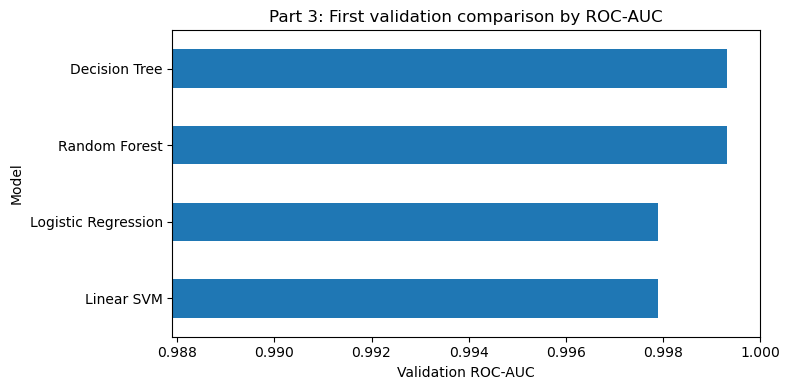

In [56]:
# =========================
# 11. Quick visualization of validation AUC
# =========================

ax = results_df.sort_values("validation_auc").plot(
    kind="barh",
    x="model",
    y="validation_auc",
    legend=False,
    figsize=(8, 4),
)
ax.set_xlabel("Validation ROC-AUC")
ax.set_ylabel("Model")
ax.set_title("Part 3: First validation comparison by ROC-AUC")
plt.xlim(max(0.0, results_df["validation_auc"].min() - 0.01), 1.0)
plt.tight_layout()
plt.show()

### Initial conclusions for Part 3

All four models were trained using the same preprocessing logic and the same stratified validation split.

The validation ROC-AUC values are very high, which means the provided features are strongly predictive of the target. At this stage, the main conclusion is not only which model has the highest validation AUC, but also whether the model looks stable when comparing train AUC to validation AUC.

The tree-based models performed especially well in this first validation test, probably because delay behavior contains nonlinear threshold effects, for example around expected delay components. Logistic Regression and Linear SVM also performed strongly, which means part of the signal is close to linearly separable after preprocessing and feature engineering.

For the next part of the project, I would continue with K-Fold Cross Validation and ROC curves for each fold. For final test-set probability predictions, it is better to choose a model with `predict_proba`, such as Logistic Regression, Decision Tree, or Random Forest. `LinearSVC` gives decision scores, not direct probabilities, unless calibration is added.

## Part 4 — Model Evaluation

In this part, the trained models are evaluated more deeply. The evaluation includes:

1. A confusion matrix for one selected model.
2. Stratified K-Fold Cross Validation.
3. ROC curves and AUC scores for every fold.
4. Train-vs-validation comparison to check whether there is evidence of overfitting.

The main metric is ROC-AUC, as required in the project instructions.

In [58]:
# =========================
# Part 4 — Evaluation imports and helper
# =========================

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc,
    roc_auc_score
)
from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone

def get_model_scores(pipeline, X_data):
    """Return continuous scores for AUC/ROC.

    Most classifiers use predict_proba. LinearSVC does not provide probabilities,
    so for LinearSVC we use decision_function instead.
    """
    model_step = pipeline.named_steps["model"]
    if hasattr(model_step, "predict_proba"):
        return pipeline.predict_proba(X_data)[:, 1]
    return pipeline.decision_function(X_data)


,Predicted 0 - Not delayed,Predicted 1 - Delayed
Actual 0 - Not delayed,8677,106
Actual 1 - Delayed,18,1411


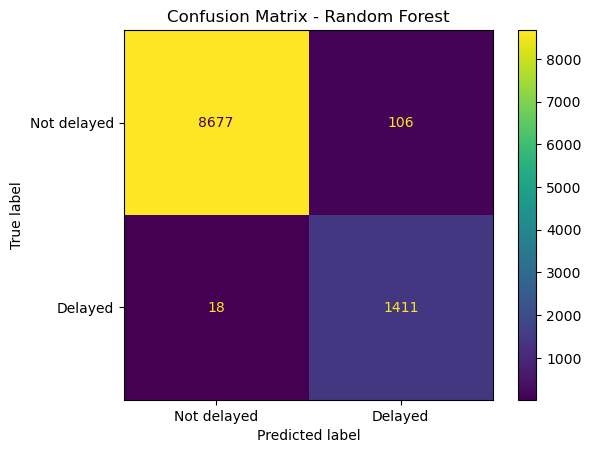

In [60]:
# =========================
# 12. Confusion Matrix on one selected model
# =========================

best_model_name = "Random Forest"
best_model = fitted_pipelines[best_model_name]

# Class predictions on the validation set
y_pred = best_model.predict(X_valid_part)

cm = confusion_matrix(y_valid_part, y_pred)

cm_df = pd.DataFrame(
    cm,
    index=["Actual 0 - Not delayed", "Actual 1 - Delayed"],
    columns=["Predicted 0 - Not delayed", "Predicted 1 - Delayed"]
)

display(cm_df)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not delayed", "Delayed"]
)
disp.plot()
plt.title(f"Confusion Matrix - {best_model_name}")
plt.show()


### Confusion Matrix explanation

The confusion matrix evaluates the Random Forest model on the validation set.

- The top-left cell represents **True Negatives**: transfers that were not delayed and were correctly predicted as not delayed.
- The bottom-right cell represents **True Positives**: transfers that were delayed and were correctly predicted as delayed.
- The top-right cell represents **False Positives**: transfers predicted as delayed although they were not actually delayed.
- The bottom-left cell represents **False Negatives**: transfers that were actually delayed but the model predicted as not delayed.

This matrix helps us understand not only the overall performance of the model, but also the types of mistakes it makes.

Running 5-Fold CV for Logistic Regression...
Running 5-Fold CV for Decision Tree...
Running 5-Fold CV for Random Forest...
Running 5-Fold CV for Linear SVM...


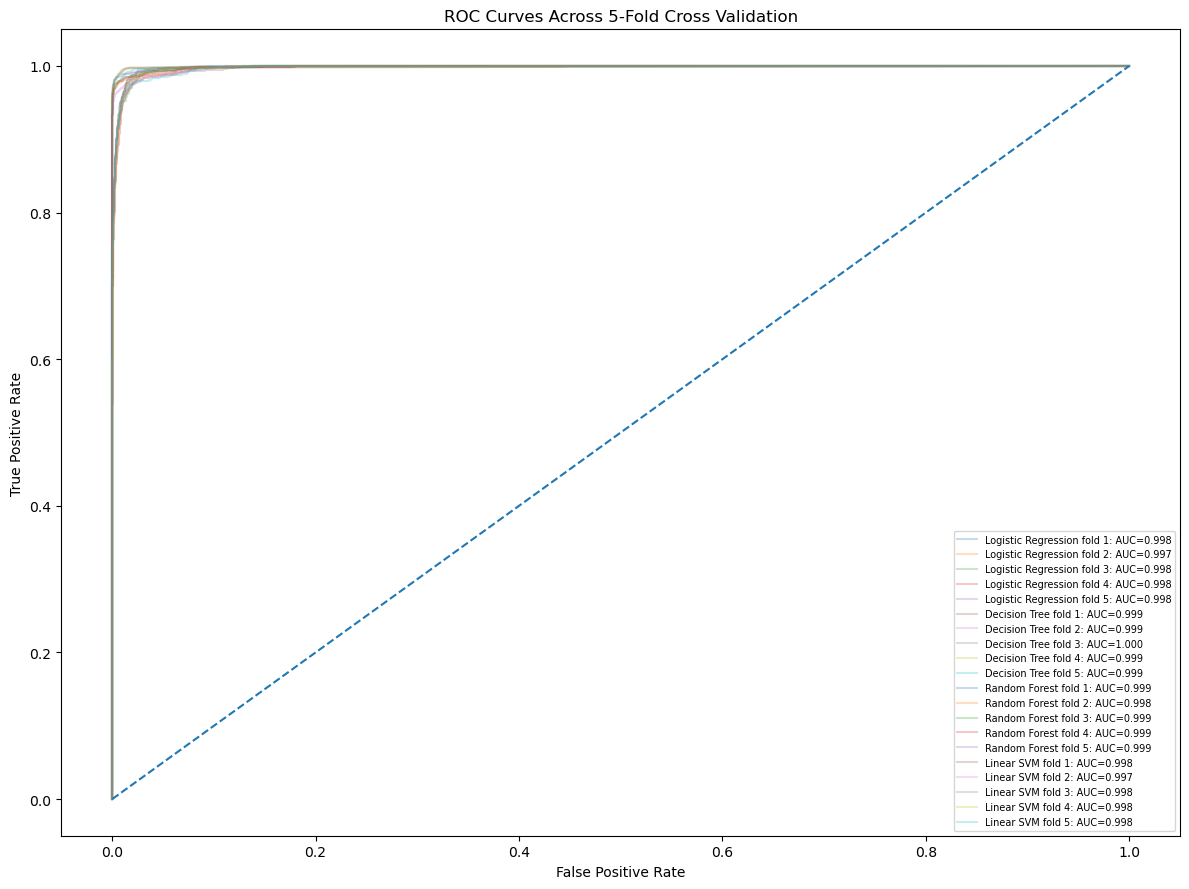

,model,mean_cv_auc,std_cv_auc,fold_1_auc,fold_2_auc,fold_3_auc,fold_4_auc,fold_5_auc
1,Decision Tree,0.9991,0.0003,0.9987,0.9991,0.9997,0.9990,0.9991
2,Random Forest,0.9989,0.0003,0.9992,0.9984,0.9991,0.9990,0.9985
0,Logistic Regression,0.9979,0.0003,0.9984,0.9975,0.9979,0.9979,0.9977
3,Linear SVM,0.9978,0.0003,0.9983,0.9975,0.9980,0.9979,0.9975


In [62]:
# =========================
# 13. Stratified K-Fold Cross Validation + ROC curves
# =========================

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_results = []

plt.figure(figsize=(12, 9))

for model_name, model in models.items():
    print(f"Running 5-Fold CV for {model_name}...")
    fold_aucs = []

    for fold, (train_idx, valid_idx) in enumerate(cv.split(X, y), start=1):
        X_tr = X.iloc[train_idx]
        X_va = X.iloc[valid_idx]
        y_tr = y.iloc[train_idx]
        y_va = y.iloc[valid_idx]

        # A new unfitted pipeline is created for each fold to avoid leakage.
        pipeline = build_model_pipeline(clone(model))
        pipeline.fit(X_tr, y_tr)

        y_scores = get_model_scores(pipeline, X_va)

        fpr, tpr, _ = roc_curve(y_va, y_scores)
        fold_auc = auc(fpr, tpr)
        fold_aucs.append(fold_auc)

        plt.plot(
            fpr,
            tpr,
            alpha=0.25,
            label=f"{model_name} fold {fold}: AUC={fold_auc:.3f}"
        )

    cv_results.append({
        "model": model_name,
        "mean_cv_auc": np.mean(fold_aucs),
        "std_cv_auc": np.std(fold_aucs),
        "fold_1_auc": fold_aucs[0],
        "fold_2_auc": fold_aucs[1],
        "fold_3_auc": fold_aucs[2],
        "fold_4_auc": fold_aucs[3],
        "fold_5_auc": fold_aucs[4],
    })

plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves Across 5-Fold Cross Validation")
plt.legend(fontsize=7)
plt.tight_layout()
plt.show()

cv_results_df = pd.DataFrame(cv_results).sort_values("mean_cv_auc", ascending=False)
display(cv_results_df)


### K-Fold Cross Validation and ROC explanation

Stratified K-Fold Cross Validation was used because the target variable is imbalanced. Stratification keeps approximately the same delayed/not-delayed ratio in every fold.

The ROC curves show the tradeoff between the True Positive Rate and the False Positive Rate. Curves closer to the upper-left corner indicate better classification performance. The AUC values summarize these curves into a single score: higher AUC means the model is better at ranking delayed transfers above non-delayed transfers.

The mean AUC shows the average model performance across folds, while the standard deviation shows stability. A low standard deviation means the model is not highly dependent on one specific train-validation split.

In [64]:
# =========================
# 14. Train vs Validation AUC and overfitting check
# =========================

overfitting_results = []

for model_name, pipeline in fitted_pipelines.items():
    train_scores = get_model_scores(pipeline, X_train_part)
    valid_scores = get_model_scores(pipeline, X_valid_part)

    train_auc = roc_auc_score(y_train_part, train_scores)
    valid_auc = roc_auc_score(y_valid_part, valid_scores)

    
    overfitting_results.append({
        "model": model_name,
        "train_auc": train_auc,
        "validation_auc": valid_auc,
        "train_validation_gap": train_auc - valid_auc,
    })

overfitting_df = pd.DataFrame(overfitting_results).sort_values("validation_auc", ascending=False)
display(overfitting_df)


,model,train_auc,validation_auc,train_validation_gap
1,Decision Tree,0.9997,0.9993,0.0004
2,Random Forest,0.9992,0.9993,-0.0001
0,Logistic Regression,0.9982,0.9979,0.0003
3,Linear SVM,0.9983,0.9979,0.0004


### Overfitting analysis

To check for overfitting, I compared the AUC on the training split with the AUC on the validation split.

If the training AUC is much higher than the validation AUC, this suggests overfitting: the model learned the training data too specifically and may not generalize well to unseen data.

In this project, the train-validation gaps are small for the strongest models, so there is **no strong evidence of significant overfitting**. The validation AUC remains close to the training AUC, and the K-Fold results also support good generalization.

To reduce the risk of overfitting, the workflow used:
- train-validation split before fitting preprocessing,
- stratified K-Fold Cross Validation,
- controlled tree complexity using `max_depth` and `min_samples_leaf`,
- class weighting for the imbalanced target,
- and excluding direct identifiers from the feature set.

Because the AUC values are very high, I also considered possible data leakage. The workflow avoids fitting preprocessing on validation/test data and does not use direct identifiers as predictive features.

## Part 5 — Prediction on the test set

After evaluating the models, the final model is trained on the **full training dataset** and then used to predict probabilities for the unlabeled test dataset.

The submission file must contain probability predictions, not just class labels. I selected **Random Forest** as the final model because it achieved extremely strong validation performance, is an ensemble model, and gives smoother probability estimates using `predict_proba`.

Although the Decision Tree had a very slightly higher mean CV AUC in this run, the difference was tiny. Random Forest was preferred as the final submission model because it is generally more robust than a single tree and produces more useful probability scores.

In [66]:
# =========================
# 15. Final training on all train data and prediction on test data
# =========================

final_model_name = "Random Forest"

final_pipeline = build_model_pipeline(clone(models[final_model_name]))

# Fit on the full training data
final_pipeline.fit(X, y)

# Predict probability of class 1: is_delayed = 1
test_probabilities = final_pipeline.predict_proba(test_df)[:, 1]

# Safety checks
assert len(test_probabilities) == len(test_df), "Number of predictions must match number of test rows."
assert np.all(test_probabilities >= 0) and np.all(test_probabilities <= 1), "Predictions must be probabilities in [0, 1]."

# The provided example submission uses transfer_id values 1, 2, 3, ...
# The test file does not contain a transfer_id column, so we create this sequence according to row order.
submission = pd.DataFrame({
    "transfer_id": np.arange(1, len(test_df) + 1),
    "predict_prob": np.round(test_probabilities, 6)
})

display(submission.head())
print("Submission shape:", submission.shape)
print("Probability range:", submission["predict_prob"].min(), "to", submission["predict_prob"].max())


,transfer_id,predict_prob
0,1,0.0875
1,2,0.9639
2,3,0.0139
3,4,0.0309
4,5,0.0170


Submission shape: (7555, 2)
Probability range: 0.002848 to 0.997062


In [68]:
# =========================
# 16. Save the submission CSV
# =========================


submission_filename = "group_027_Submission.csv"
submission_path = DATA_DIR / submission_filename

submission.to_csv(submission_path, index=False)

print(f"Saved submission file to: {submission_path}")
print("Submission columns:", submission.columns.tolist())
print("Number of rows:", len(submission))


Saved submission file to: group_027_Submission.csv
Submission columns: ['transfer_id', 'predict_prob']
Number of rows: 7555


### Part 5 explanation

The final Random Forest model was fitted on the entire training dataset after model selection. This is appropriate because once the model choice is made using validation and cross-validation, all available labeled data can be used to train the final model.

For each row in the test set, the model outputs the probability that the transfer will be delayed by more than 30 minutes. The output file follows the required submission format with two columns:

1. `transfer_id` — a sequential identifier matching the row order of the test file.
2. `predict_prob` — the predicted probability that `is_delayed = 1`.

Before saving the file, I checked that:
- the number of predictions equals the number of test rows,
- all predictions are valid probabilities between 0 and 1,
- and the output columns match the example submission format.
  
